       🎓 WELCOME TO STUDENT MARKS ANALYZER 🎓       
Select an option:
  [1] Upload a CSV File (from Google Colab / Computer)
  [2] Enter Student Marks Manually
  [3] Run Quick Demo with Pre-loaded Sample Dataset
Enter choice (1/2/3): 1

📥 Please upload your student marks CSV file:


Saving student_marks_demo_75.csv to student_marks_demo_75 (1).csv
✅ Successfully loaded 'student_marks_demo_75 (1).csv'!

                     🎓 STUDENT PERFORMANCE REPORT 🎓                     
 Rank  Roll_No              Name  Maths  Physics  Electrical  EVS  AI  C++  Total_Marks  Percentage        Status           Grade
    1      101      Aarav Sharma     98       95          92   96  99   97          577   96.166667          PASS O (Outstanding)
    2      173     Divya Agarwal     96       93          89   98  97   95          568   94.666667          PASS O (Outstanding)
    3      137         Riya Nair     95       92          88   98  96   94          563   93.833333          PASS O (Outstanding)
    4      125    Meera Tripathi     94       91          87   97  95   93          557   92.833333          PASS O (Outstanding)
    5      162        Vidhi Nair     93       90          86   97  95   92          553   92.166667          PASS O (Outstanding)
    6      132      Prana

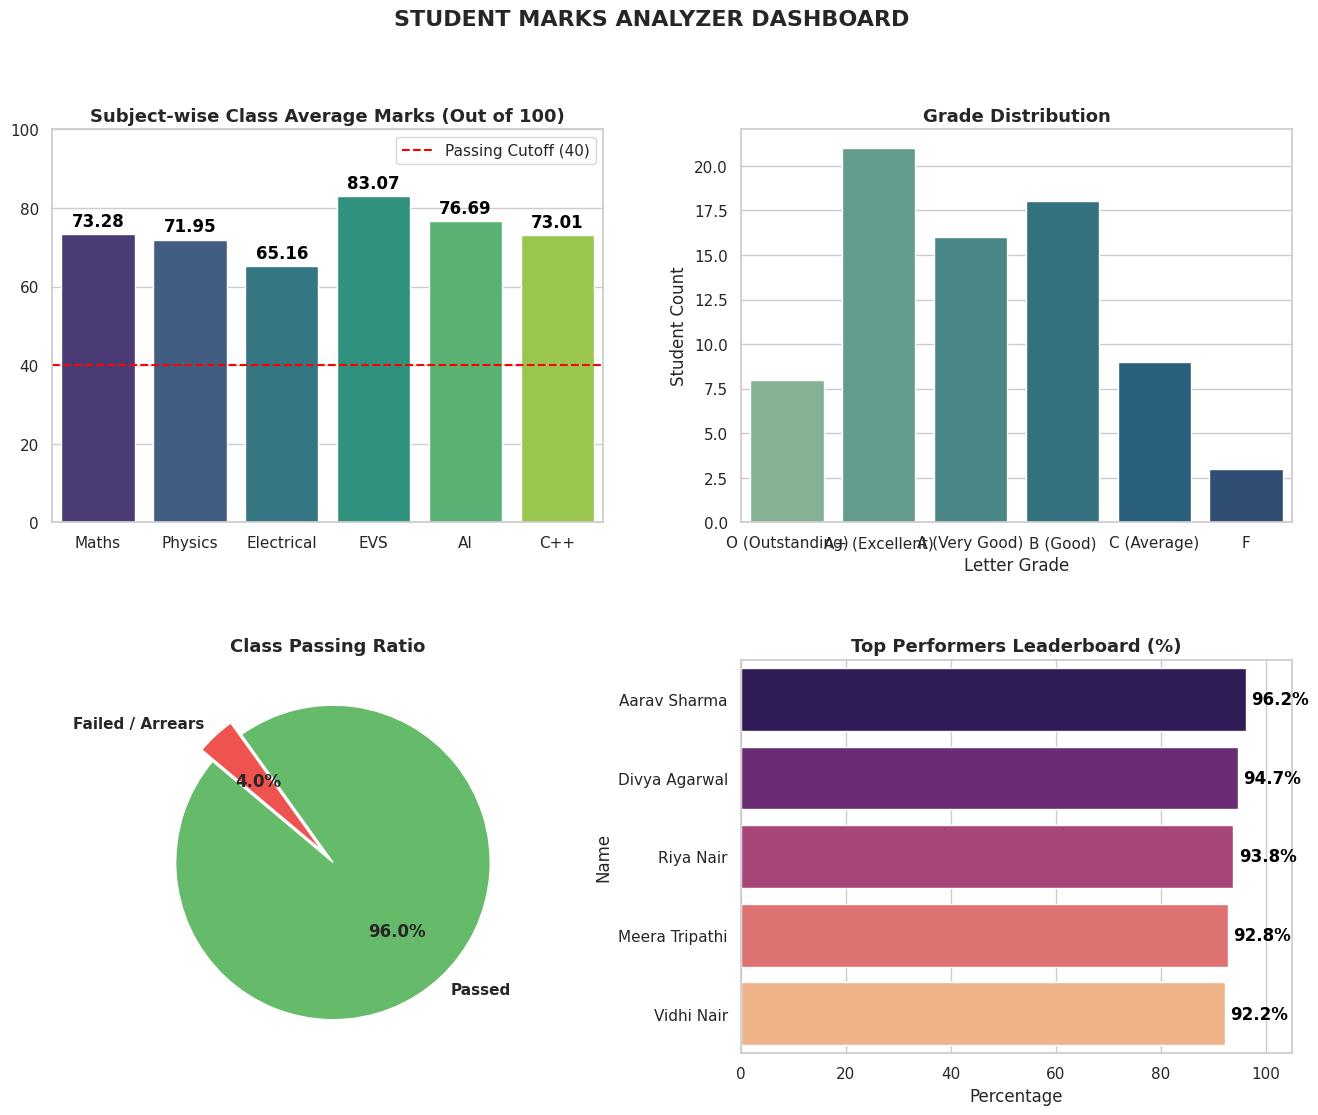

In [5]:
# ==============================================================================
# PROJECT TITLE: STUDENT MARKS ANALYZER
# TECH STACK: Python, NumPy, Pandas, Matplotlib, Seaborn
# AUTHOR: B.Tech First Year Mini-Project
# ==============================================================================

import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set aesthetics for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ------------------------------------------------------------------------------
# 1. HELPER FUNCTIONS: GRADING & STATUS
# ------------------------------------------------------------------------------


def calculate_grade(percentage, passed_all):
    """Assigns letter grades based on percentage and pass criteria."""
    if not passed_all or percentage < 40:
        return "F"
    elif percentage >= 90:
        return "O (Outstanding)"
    elif percentage >= 80:
        return "A+ (Excellent)"
    elif percentage >= 70:
        return "A (Very Good)"
    elif percentage >= 60:
        return "B (Good)"
    elif percentage >= 50:
        return "C (Average)"
    else:
        return "P (Pass)"


# ------------------------------------------------------------------------------
# 2. DATA INGESTION: CSV UPLOAD, MANUAL INPUT, OR DEMO DATA
# ------------------------------------------------------------------------------


def get_demo_data():
    """Generates synthetic student marks dataset for quick demo."""
    data = {
        "Roll_No": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
        "Name": [
            "Aarav",
            "Ananya",
            "Rohan",
            "Priya",
            "Kabir",
            "Isha",
            "Aditya",
            "Sneha",
            "Vikram",
            "Riya",
        ],
        "Mathematics": [95, 38, 78, 88, 56, 92, 45, 67, 85, 34],
        "Physics": [89, 42, 65, 91, 50, 85, 40, 72, 79, 39],
        "Chemistry": [92, 35, 70, 85, 62, 89, 52, 68, 82, 41],
        "Computer_Science": [98, 55, 82, 94, 60, 95, 48, 75, 88, 45],
        "English": [85, 60, 75, 89, 65, 88, 58, 70, 80, 50],
    }
    return pd.DataFrame(data)


def upload_csv():
    """Handles Google Colab file upload."""
    try:
        from google.colab import files

        print("\n📥 Please upload your student marks CSV file:")
        uploaded = files.upload()
        for filename in uploaded.keys():
            df = pd.read_csv(io.BytesIO(uploaded[filename]))
            print(f"✅ Successfully loaded '{filename}'!")
            return df
    except ImportError:
        # Fallback if running locally in Jupyter/VS Code instead of Colab
        path = input("Enter local CSV file path: ")
        return pd.read_csv(path)


def manual_entry():
    """Allows manual entry of students and subjects."""
    num_students = int(input("\nEnter total number of students: "))
    subjects = [
        s.strip()
        for s in input(
            "Enter subject names (comma separated, e.g., Math, Physics, CS): "
        ).split(",")
    ]

    records = []
    print("\n--- Enter Student Details (Max marks per subject = 100) ---")
    for i in range(num_students):
        print(f"\nStudent #{i+1}:")
        roll = input("  Roll No: ")
        name = input("  Name: ")
        student_dict = {"Roll_No": roll, "Name": name}

        for subj in subjects:
            while True:
                try:
                    marks = float(input(f"  Marks in {subj} (0-100): "))
                    if 0 <= marks <= 100:
                        student_dict[subj] = marks
                        break
                    else:
                        print("  ⚠️ Marks must be between 0 and 100. Try again.")
                except ValueError:
                    print("  ⚠️ Invalid input. Enter a numeric value.")
        records.append(student_dict)

    return pd.DataFrame(records)


# ------------------------------------------------------------------------------
# 3. CORE ANALYSIS FUNCTION
# ------------------------------------------------------------------------------


def analyze_student_data(df):
    """Performs statistical analysis using NumPy and Pandas."""
    # Identify subject columns (excluding Roll_No and Name)
    non_subject_cols = ["Roll_No", "Name"]
    subject_cols = [col for col in df.columns if col not in non_subject_cols]

    # Convert subject columns to numeric (handling errors if any string exists)
    for col in subject_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

    # 1. Row-level calculations
    num_subjects = len(subject_cols)
    max_total = num_subjects * 100

    df["Total_Marks"] = df[subject_cols].sum(axis=1)
    df["Percentage"] = (df["Total_Marks"] / max_total) * 100

    # Pass Criteria: >= 40 in EACH subject
    df["Passed_All"] = (df[subject_cols] >= 40).all(axis=1)
    df["Status"] = df["Passed_All"].apply(
        lambda x: "PASS" if x else "FAIL (Arrear)"
    )
    df["Grade"] = df.apply(
        lambda r: calculate_grade(r["Percentage"], r["Passed_All"]), axis=1
    )

    # Class Ranking
    df["Rank"] = df["Total_Marks"].rank(ascending=False, method="min").astype(int)
    df.sort_values(by="Rank", inplace=True)
    df.reset_index(drop=True, inplace=True)

    # --------------------------------------------------------------------------
    # PRINT TABULAR REPORT
    # --------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("                     🎓 STUDENT PERFORMANCE REPORT 🎓                     ")
    print("=" * 80)
    display_cols = (
        ["Rank", "Roll_No", "Name"]
        + subject_cols
        + ["Total_Marks", "Percentage", "Status", "Grade"]
    )
    print(df[display_cols].to_string(index=False))

    # --------------------------------------------------------------------------
    # 2. CLASS-LEVEL METRICS & NUMPY STATS
    # --------------------------------------------------------------------------
    total_students = len(df)
    pass_count = (df["Status"] == "PASS").sum()
    fail_count = total_students - pass_count
    pass_ratio = (pass_count / total_students) * 100

    # NumPy calculations on Class Percentages
    pct_array = df["Percentage"].to_numpy()
    mean_pct = np.mean(pct_array)
    median_pct = np.median(pct_array)
    std_pct = np.std(pct_array)
    q25 = np.percentile(pct_array, 25)
    q75 = np.percentile(pct_array, 75)

    topper = df.loc[df["Percentage"].idxmax()]
    least_scorer = df.loc[df["Percentage"].idxmin()]

    print("\n" + "=" * 80)
    print("                     📊 CLASS OVERALL SUMMARY 📊                        ")
    print("=" * 80)
    print(f"👥 Total Students Assessed   : {total_students}")
    print(f"✅ Passed Students            : {pass_count}")
    print(f"❌ Failed / Arrears           : {fail_count}")
    print(f"📈 Passing Ratio / Rate       : {pass_ratio:.2f}%")
    print("-" * 80)
    print(f"🏆 Class Topper               : {topper['Name']} (Roll: {topper['Roll_No']})")
    print(f"   Score                      : {topper['Total_Marks']}/{max_total} ({topper['Percentage']:.2f}%) - Grade: {topper['Grade']}")
    print(f"📉 Lowest Scorer              : {least_scorer['Name']} (Roll: {least_scorer['Roll_No']})")
    print(f"   Score                      : {least_scorer['Total_Marks']}/{max_total} ({least_scorer['Percentage']:.2f}%) - Grade: {least_scorer['Grade']}")
    print("-" * 80)
    print("📐 Statistical Metrics (NumPy on Class Percentages):")
    print(f"   • Mean (Average) %         : {mean_pct:.2f}%")
    print(f"   • Median %                 : {median_pct:.2f}%")
    print(f"   • Standard Deviation (σ)   : {std_pct:.2f}")
    print(f"   • Interquartile Range (IQR): 25th %ile = {q25:.2f}%, 75th %ile = {q75:.2f}%")
    print("=" * 80)

    # --------------------------------------------------------------------------
    # 3. SUBJECT-WISE BREAKDOWN
    # --------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("                     📚 SUBJECT-WISE BREAKDOWN 📚                        ")
    print("=" * 80)
    subj_summary = []
    for subj in subject_cols:
        marks = df[subj].to_numpy()
        highest = np.max(marks)
        lowest = np.min(marks)
        avg = np.mean(marks)
        subj_topper = df.loc[df[subj] == highest, "Name"].values[0]

        subj_summary.append(
            {
                "Subject": subj,
                "Highest": highest,
                "Topper": subj_topper,
                "Lowest": lowest,
                "Average": round(avg, 2),
                "Passing (>=40)": f"{(marks >= 40).sum()}/{total_students}",
            }
        )
    subj_df = pd.DataFrame(subj_summary)
    print(subj_df.to_string(index=False))
    print("=" * 80)

    # --------------------------------------------------------------------------
    # 4. VISUALIZATIONS (PLOTS)
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    plt.subplots_adjust(hspace=0.35, wspace=0.25)

    # Plot 1: Subject Averages
    avg_marks = [s["Average"] for s in subj_summary]
    sns.barplot(
        x=subject_cols,
        y=avg_marks,
        ax=axes[0, 0],
        palette="viridis",
        hue=subject_cols,
        legend=False,
    )
    axes[0, 0].set_title(
        "Subject-wise Class Average Marks (Out of 100)",
        fontsize=13,
        weight="bold",
    )
    axes[0, 0].set_ylim(0, 100)
    axes[0, 0].axhline(40, color="red", linestyle="--", label="Passing Cutoff (40)")
    for i, v in enumerate(avg_marks):
        axes[0, 0].text(
            i, v + 2, f"{v}", ha="center", weight="bold", color="black"
        )
    axes[0, 0].legend()

    # Plot 2: Grade Distribution
    grade_order = [
        "O (Outstanding)",
        "A+ (Excellent)",
        "A (Very Good)",
        "B (Good)",
        "C (Average)",
        "P (Pass)",
        "F",
    ]
    present_grades = [g for g in grade_order if g in df["Grade"].values]
    sns.countplot(
        x="Grade",
        data=df,
        order=present_grades,
        ax=axes[0, 1],
        palette="crest",
        hue="Grade",
        legend=False,
    )
    axes[0, 1].set_title("Grade Distribution", fontsize=13, weight="bold")
    axes[0, 1].set_xlabel("Letter Grade")
    axes[0, 1].set_ylabel("Student Count")

    # Plot 3: Pass vs Fail Ratio
    axes[1, 0].pie(
        [pass_count, fail_count],
        labels=["Passed", "Failed / Arrears"],
        autopct="%1.1f%%",
        startangle=140,
        colors=["#66bb6a", "#ef5350"],
        explode=(0.05, 0.05),
        textprops={"weight": "bold"},
    )
    axes[1, 0].set_title("Class Passing Ratio", fontsize=13, weight="bold")

    # Plot 4: Top 5 Performers
    top_5 = df.head(5)
    sns.barplot(
        x="Percentage",
        y="Name",
        data=top_5,
        ax=axes[1, 1],
        palette="magma",
        hue="Name",
        legend=False,
    )
    axes[1, 1].set_title(
        "Top Performers Leaderboard (%)", fontsize=13, weight="bold"
    )
    axes[1, 1].set_xlim(0, 105)
    for i, val in enumerate(top_5["Percentage"]):
        axes[1, 1].text(
            val + 1, i, f"{val:.1f}%", va="center", weight="bold", color="black"
        )

    plt.suptitle("STUDENT MARKS ANALYZER DASHBOARD", fontsize=16, weight="bold")
    plt.show()


# ------------------------------------------------------------------------------
# 4. MAIN INTERACTION MENU
# ------------------------------------------------------------------------------


def main():
    print("=" * 60)
    print("       🎓 WELCOME TO STUDENT MARKS ANALYZER 🎓       ")
    print("=" * 60)
    print("Select an option:")
    print("  [1] Upload a CSV File (from Google Colab / Computer)")
    print("  [2] Enter Student Marks Manually")
    print("  [3] Run Quick Demo with Pre-loaded Sample Dataset")
    print("=" * 60)

    choice = input("Enter choice (1/2/3): ").strip()

    if choice == "1":
        df = upload_csv()
    elif choice == "2":
        df = manual_entry()
    elif choice == "3":
        print("\n✨ Loading sample dataset with 10 students...")
        df = get_demo_data()
    else:
        print("❌ Invalid choice. Loading sample demo data by default.")
        df = get_demo_data()

    if df is not None and not df.empty:
        analyze_student_data(df)
    else:
        print("❌ Error: No valid data found.")


# Run the program
if __name__ == "__main__":
    main()